# Filtros lineares e não lineares

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

### Upload de imagem

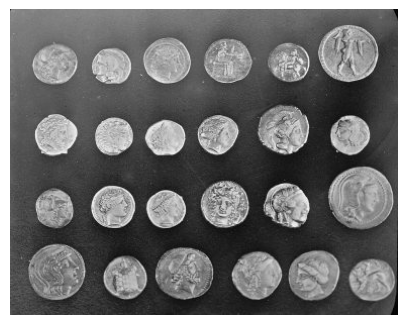

In [ ]:
imagem = data.coins()

plt.figure(figsize=(5, 5))
plt.imshow(imagem, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
def convolucao(img, tamanho, op):
    pad = tamanho // 2
    img_pad = np.pad(img, pad, mode='edge')
    saida = np.zeros(img.shape, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            janela = img_pad[i:i + tamanho, j:j + tamanho]
            saida[i, j] = op(janela)

    return np.round(saida).astype(np.uint8)

### Filtros

In [ ]:
def filtro_media(img, tamanho=5):
    kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
    return convolucao(img, tamanho, lambda janela: np.sum(janela * kernel))


def filtro_mediana(img, tamanho=5):
    return convolucao(img, tamanho, lambda janela: np.median(janela))


def filtro_moda(img, tamanho=5):
    return convolucao(img, tamanho, lambda janela: np.bincount(janela.ravel()).argmax())



def filtro_maxima(img, tamanho=5):
    return convolucao(img, tamanho, lambda janela: np.max(janela))


### Comparação

In [ ]:
def comparar(img, filtros, tamanho):
    fig, eixos = plt.subplots(len(filtros), 2, figsize=(8, 4 * len(filtros)))
    for linha, (nome, filtro) in enumerate(filtros.items()):
        img_filt = filtro(img, tamanho)
        eixos[linha, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
        eixos[linha, 0].set_title('Imagem original')
        eixos[linha, 1].imshow(img_filt, cmap='gray', vmin=0, vmax=255)
        eixos[linha, 1].set_title(f'Filtro {nome} {tamanho}x{tamanho}')
        for ax in eixos[linha]:
            ax.axis('off')
    plt.tight_layout()
    plt.show()

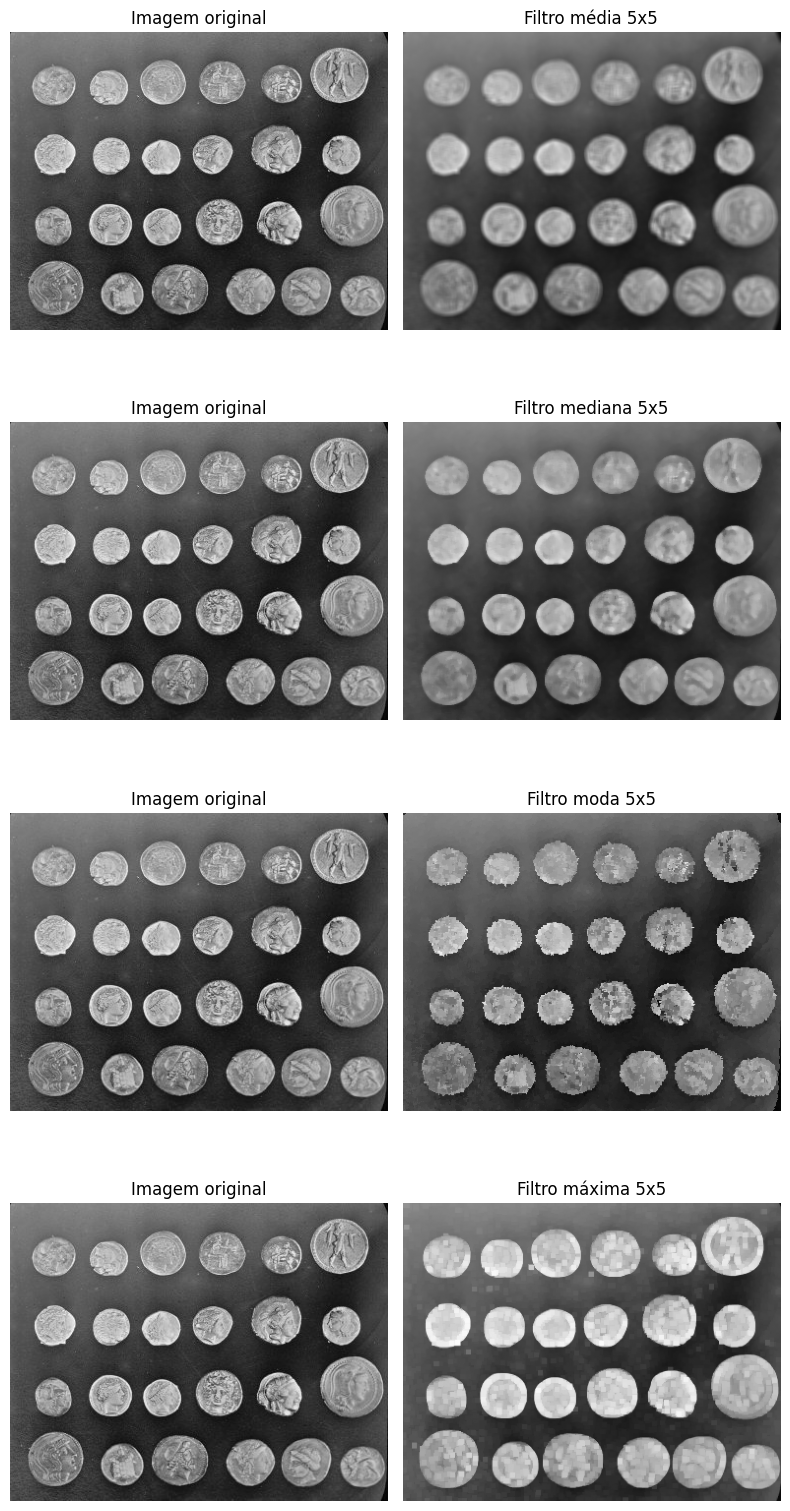

In [ ]:
filtros = {
    'média': filtro_media,
    'mediana': filtro_mediana,
    'moda': filtro_moda,
    'máxima': filtro_maxima,
}
comparar(imagem, filtros, 5)